## A sensor contains useful low-frequency signals and unwanted high-frequency interference:
    sampling frequency = 200 Hz
    duration = 3 seconds
    useful frequencies = 5, 10, 20 Hz
    unwanted frequencies = 80, 95 Hz
    passband = 0-20 Hz
    maximum passband error = 10%
    stopband = 80-100 Hz
    required stopband attenuation = at least 20 dB

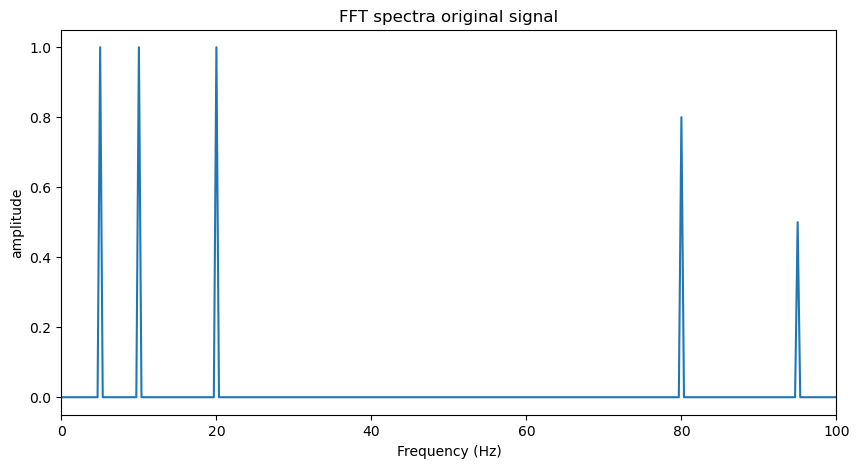

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter, freqz

fs, duration = 200, 3
N = fs * duration
t = np.arange(N) / fs
clean = np.sin(2 * np.pi * 5 * t) + np.sin(2 * np.pi * 10 * t) + np.sin(2 * np.pi * 20 * t)
noise = 0.8 * np.sin(2 * np.pi * 80 * t) + 0.5 * np.sin(2 * np.pi * 95 * t)
x = clean + noise

freq_fft = np.fft.rfftfreq(N, d=1/fs)
amplitude = np.abs(np.fft.rfft(x)) / N
amplitude[1:-1] *= 2
plt.figure(figsize=(10, 5))
plt.plot(freq_fft, amplitude)
plt.xlim(0, 100)
plt.xlabel("Frequency (Hz)")
plt.ylabel("amplitude")
plt.title("FFT spectra original signal")
plt.show()

## First approach:

### Adding zeros at unwanted frequencies and then adding poles if necessary

passband error (%): 19.099852155940987
stopband (dB): 53.07493488267943


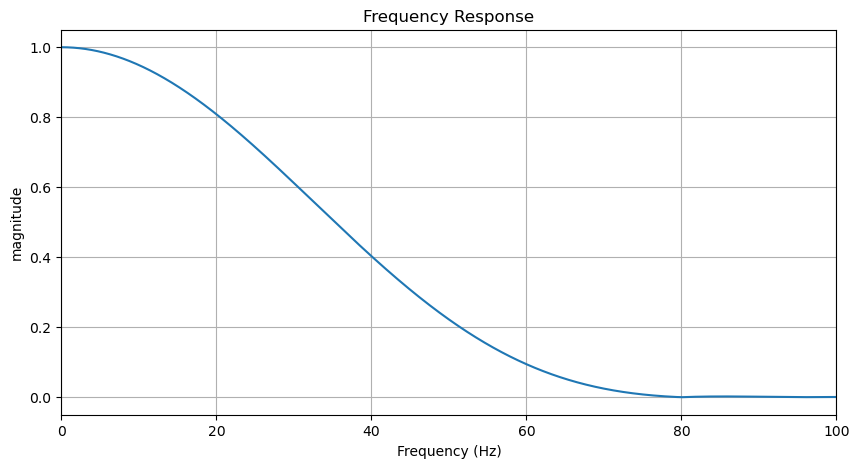

In [20]:
theta80 = 2 * np.pi * 80 / fs
b1 = np.array([1, -2 * np.cos(theta80), 1])
theta95 = 2 * np.pi * 95 / fs
b2 = np.array([1, -2 * np.cos(theta95), 1])
b = np.convolve(b1, b2)
b = b / sum(b)
f, H = freqz(b, [1], worN = 2048, fs=fs)
magnitude = np.abs(H)

passband = f <= 20
passband_error = np.max(np.abs(magnitude[passband] - 1)) * 100
print("passband error (%):", passband_error)
stopband = (f >= 80) & (f <= 100)
stopband_att_dB = -20 * np.log10(np.max(magnitude[stopband]))
print("stopband (dB):", stopband_att_dB)
plt.figure(figsize=(10, 5))
plt.plot(f, magnitude)
plt.xlim(0, 100)
plt.xlabel("Frequency (Hz)")
plt.ylabel("magnitude")
plt.title("Frequency Response")
plt.grid(True)
plt.show()

The stopband requirement is satisfied strongly, however, passband requirement is not satisfied.

### Adding poles at 30 Hz ( converting FIR to IIR )

rho = 0.5 : passband error = 12.370210250543135
rho = 0.5 : stopband = 61.47165232716711
rho = 0.6 : passband error = 2.9322023252238427
rho = 0.6 : stopband = 62.53796914047109
rho = 0.7 : passband error = 10.954941467355251
rho = 0.7 : stopband = 63.325364684977174
rho = 0.8 : passband error = 28.289908256184404
rho = 0.8 : stopband = 63.84356968435816
rho = 0.9 : passband error = 44.0643045260414
rho = 0.9 : stopband = 64.12288899618302


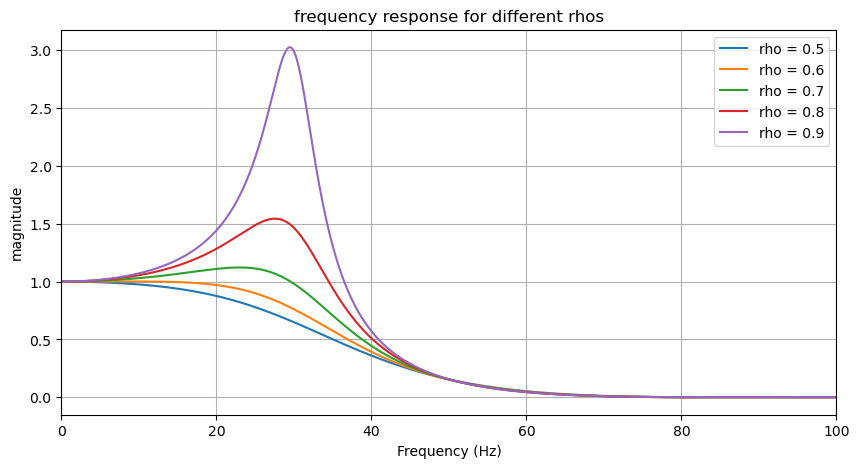

In [21]:
fb = 30
theta_b = 2 * np.pi * fb / fs
rhos = [0.5, 0.60, 0.70, 0.80, 0.90]
plt.figure(figsize=(10, 5))
for rho in rhos:
    a = np.array([1, -2 * np.cos(theta_b) * rho, rho ** 2])
    k = sum(a) / sum(b)
    b_iir = k * b
    f, H2 = freqz(b_iir, a, worN=2048, fs=fs)
    magnitude2 = np.abs(H2)
    passband_error = np.max(np.abs(magnitude2[passband] - 1)) * 100
    print(f"rho = {rho} : passband error = {passband_error}")
    stopband_att_dB = -20 * np.log10(np.max(magnitude2[stopband]))
    print(f"rho = {rho} : stopband = {stopband_att_dB}")
    plt.plot(f, magnitude2, label = f"rho = {rho}")
plt.xlabel("Frequency (Hz)")
plt.ylabel("magnitude")
plt.xlim(0, 100)
plt.title("frequency response for different rhos")
plt.grid(True)
plt.legend()
plt.show()
    

At fb = 30 Hz, only rho = 0.60 satisfies two requirements.

### Applying the selected IIR filter

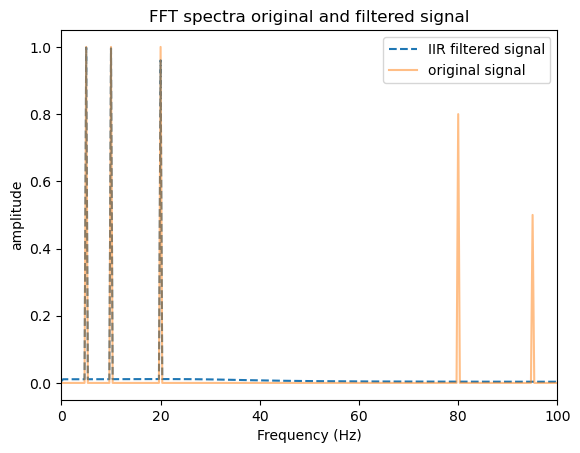

In [22]:
fb, rho = 30, 0.60
theta_b = 2 * np.pi * fb / fs
a = np.array([1, -2 * np.cos(theta_b) * rho, rho **2])
k = sum(a) / sum(b)
b_iir = k * b

iir_out = lfilter(b_iir, a, x)
iir_amplitude = np.abs(np.fft.rfft(iir_out)) / N
iir_amplitude[1:-1] *= 2
plt.plot(freq_fft, iir_amplitude, label = "IIR filtered signal", linestyle="--")
plt.plot(freq_fft, amplitude, label = "original signal", alpha=0.5)
plt.legend()
plt.xlabel("Frequency (Hz)")
plt.ylabel("amplitude")
plt.xlim(0, 100)
plt.title("FFT spectra original and filtered signal")
plt.show()

However, I should mention that the 20 Hz component is not perfectly preserved: poles at 30 Hz have affected 20 Hz 

## Second approach:

Instead of choosing separate zeros at 80 and 95 Hz, I will place repeated zeros at the Nyquist frequency

    (M) is the number of the repeated factors and also the FIR filter order. 

    Increasing (M) makes the response decrease faster as frequency increases. That helps suppress high frequencies, but can also attenuate useful components such as 20 Hz.

M = 1 : passband error (%)= 4.880
	stopband (dB) = 10.213
M = 2 : passband error (%)= 9.522
	stopband (dB) = 20.425
M = 3 : passband error (%)= 13.938
	stopband (dB) = 30.638
M = 4 : passband error (%)= 18.138
	stopband (dB) = 40.851


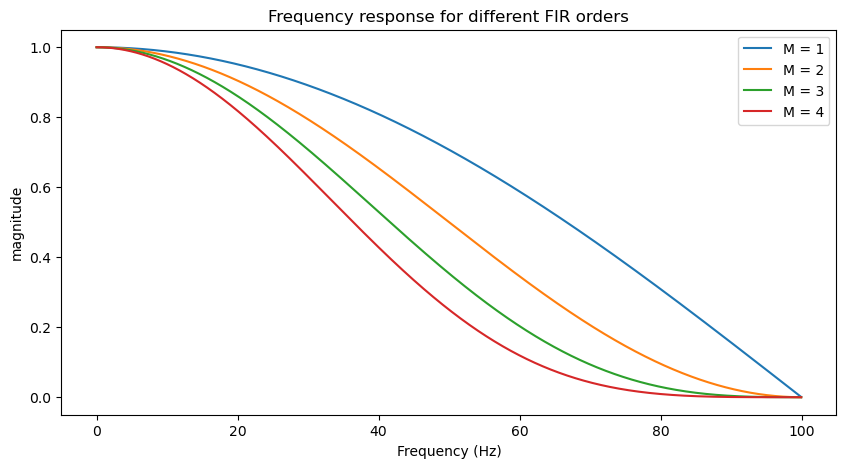

In [28]:
orders = [1, 2, 3, 4]
plt.figure(figsize=(10, 5))

for M in orders:
    b = np.array([1.0])
    for i in range(M):
        b = np.convolve(b, [1, 1])
    b = 1 / sum(b) * b
    f, H = freqz(b, [1], worN = 2048, fs=fs)
    magnitude = np.abs(H)
    passband = (f >= 0) & (f <= 20)
    passband_error = np.max(np.abs(magnitude[passband] - 1)) * 100
    stopband = (f >= 80) & (f <= 100)
    stopband_att_dB = -20 * np.log10(np.max(magnitude[stopband]))
    print(f"M = {M} : passband error (%)= {passband_error:.3f}\n\tstopband (dB) = {stopband_att_dB:.3f}")
    plt.plot(f, magnitude, label = f"M = {M}")
plt.xlabel("Frequency (Hz)")
plt.ylabel("magnitude")
plt.title("Frequency response for different FIR orders")
plt.legend()
plt.show()

M = 2 satisfies both requirements

### Applying the selected FIR filter

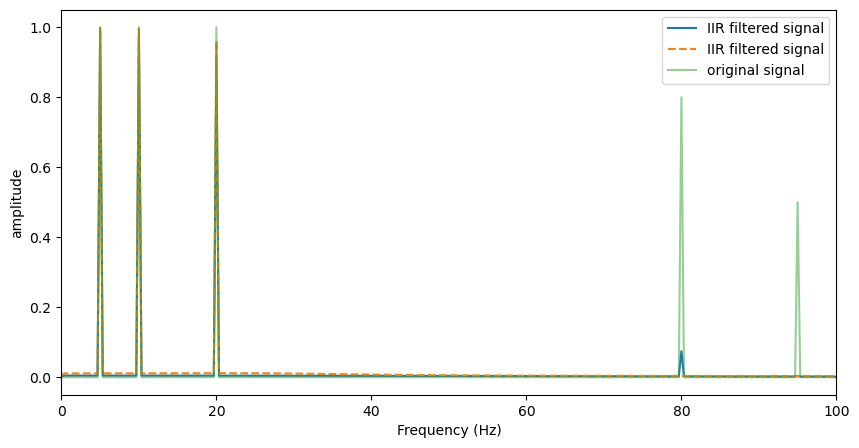

In [24]:
# Apply to noisy signal
b = np.convolve([1, 1], [1, 1])
b = b / sum(b)
fir_out = lfilter(b, [1], x)

fir_freq_fft = np.fft.rfftfreq(N, d=1/fs)
fir_amplitude = np.abs(np.fft.rfft(fir_out)) / N
fir_amplitude[1:-1] *= 2
plt.figure(figsize=(10, 5))
plt.plot(fir_freq_fft, fir_amplitude, label = "IIR filtered signal")
plt.plot(iir_freq_fft, iir_amplitude, label = "IIR filtered signal", linestyle="--")
plt.plot(freq_fft, amplitude, label = "original signal", alpha=0.5)
plt.xlabel("Frequency (Hz)")
plt.ylabel("amplitude")
plt.xlim(0, 100)
plt.legend()
plt.show()

### comparing the amplitudes numerically

In [15]:
for hz in [5, 10, 20, 80, 95]:
    idx = np.argmin(np.abs(freq_fft - hz))

    print(f"{hz} Hz")
    print(f"Original: {amplitude[idx]:.3f}")
    print(f"FIR:      {fir_amplitude[idx]:.3f}")
    print(f"IIR:      {iir_amplitude[idx]:.3f}")
    print("------")

5 Hz
Original: 1.000
FIR:      0.993
IIR:      0.999
------
10 Hz
Original: 1.000
FIR:      0.974
IIR:      0.999
------
20 Hz
Original: 1.000
FIR:      0.902
IIR:      0.972
------
80 Hz
Original: 0.800
FIR:      0.074
IIR:      0.006
------
95 Hz
Original: 0.500
FIR:      0.003
IIR:      0.004
------


### Conclusion:

    First approach (IIR Filter):
        Better preservation of the useful frequencies and stronger stopband attenuation, but includes feedback and has frequency-dependent delay.
    
    Scond approach (FIR Filter):
        Simpler, has only three coefficients and a constant group delay of 5 ms, but attenuates 20 Hz more strongly.